10322005
Muhammad Fathir Rizqy Fadli


In [13]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl

In [ ]:
# Mendefinisikan rentang nilai untuk setiap variabel.
# Kelembapan tanah diukur dari 0% hingga 100%.
# Suhu udara dari 0°C hingga 50°C.
# Durasi penyiraman dari 0 hingga 60 detik.
kelembapan_tanah = ctrl.Antecedent(np.arange(0, 101, 1), 'kelembapan_tanah')
suhu_udara = ctrl.Antecedent(np.arange(0, 51, 1), 'suhu_udara')
durasi_penyiraman = ctrl.Consequent(np.arange(0, 61, 1), 'durasi_penyiraman')

In [15]:
# Fungsi keanggotaan untuk Kelembapan Tanah
kelembapan_tanah['kering'] = fuzz.trimf(kelembapan_tanah.universe, [0, 0, 40])
kelembapan_tanah['lembap'] = fuzz.trimf(kelembapan_tanah.universe, [20, 50, 80])
kelembapan_tanah['basah'] = fuzz.trimf(kelembapan_tanah.universe, [60, 100, 100])

# Fungsi keanggotaan untuk Suhu Udara
suhu_udara['dingin'] = fuzz.trimf(suhu_udara.universe, [0, 0, 20])
suhu_udara['normal'] = fuzz.trimf(suhu_udara.universe, [15, 25, 35])
suhu_udara['panas'] = fuzz.trimf(suhu_udara.universe, [30, 50, 50])

# Fungsi keanggotaan untuk Durasi Penyiraman
durasi_penyiraman['singkat'] = fuzz.trimf(durasi_penyiraman.universe, [0, 0, 25])
durasi_penyiraman['sedang'] = fuzz.trimf(durasi_penyiraman.universe, [15, 30, 45])
durasi_penyiraman['lama'] = fuzz.trimf(durasi_penyiraman.universe, [35, 60, 60])

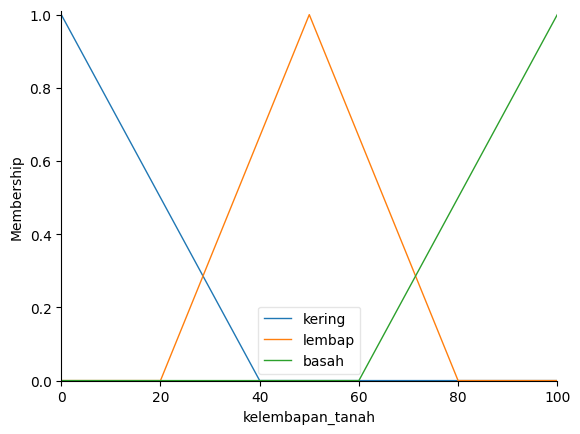

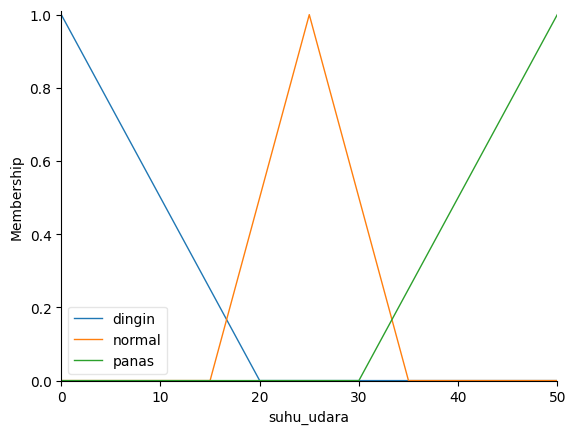

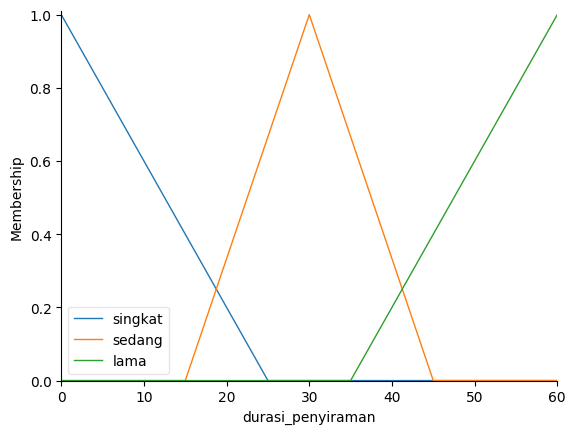

In [16]:
kelembapan_tanah.view()
suhu_udara.view()
durasi_penyiraman.view()

In [17]:
# Aturan 1: Jika tanah KERING dan suhu PANAS, maka siram LAMA.
aturan1 = ctrl.Rule(kelembapan_tanah['kering'] & suhu_udara['panas'], durasi_penyiraman['lama'])

# Aturan 2: Jika tanah KERING dan suhu NORMAL, maka siram SEDANG.
aturan2 = ctrl.Rule(kelembapan_tanah['kering'] & suhu_udara['normal'], durasi_penyiraman['sedang'])

# Aturan 3: Jika tanah LEMBAP dan suhu PANAS, maka siram SEDANG.
aturan3 = ctrl.Rule(kelembapan_tanah['lembap'] & suhu_udara['panas'], durasi_penyiraman['sedang'])

# Aturan 4: Jika tanah LEMBAP dan suhu NORMAL, maka siram SINGKAT.
aturan4 = ctrl.Rule(kelembapan_tanah['lembap'] & suhu_udara['normal'], durasi_penyiraman['singkat'])

# Aturan 5: Jika tanah BASAH, maka siram SINGKAT (artinya tidak perlu siram).
aturan5 = ctrl.Rule(kelembapan_tanah['basah'], durasi_penyiraman['singkat'])

# Aturan 6: Jika suhu DINGIN, maka siram SINGKAT.
aturan6 = ctrl.Rule(suhu_udara['dingin'], durasi_penyiraman['singkat'])


In [18]:
# Menggabungkan semua aturan ke dalam satu sistem kontrol
sistem_kontrol = ctrl.ControlSystem([aturan1, aturan2, aturan3, aturan4, aturan5, aturan6])

# Membuat simulasi dari sistem kontrol yang sudah dibuat
sistem_siram = ctrl.ControlSystemSimulation(sistem_kontrol)

Input Kelembapan Tanah: 25%
Input Suhu Udara: 50°C
---------------------------------------------
Hasil Durasi Penyiraman: 42.47 detik


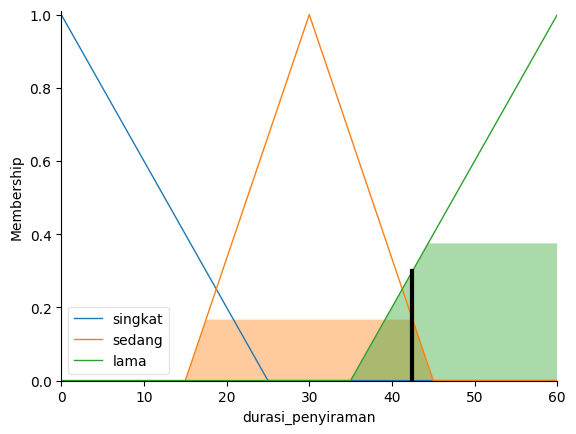

In [24]:


input_kelembapan = 25
input_suhu = 50

sistem_siram.input['kelembapan_tanah'] = input_kelembapan
sistem_siram.input['suhu_udara'] = input_suhu

# Menjalankan perhitungan fuzzy
sistem_siram.compute()

# Mendapatkan hasil output (nilai konkret)
hasil_durasi = sistem_siram.output['durasi_penyiraman']

# Menampilkan hasil
print("=============================================")
print(f"Input Kelembapan Tanah: {input_kelembapan}%")
print(f"Input Suhu Udara: {input_suhu}°C")
print("---------------------------------------------")
print(f"Hasil Durasi Penyiraman: {hasil_durasi:.2f} detik")
print("=============================================")

durasi_penyiraman.view(sim=sistem_siram)